### Let's preprocess FeTa !!

1. Load the images and their corresponding segmentations as pairs
2. Reorient to RAS (right-anterior-superior), some orientations are LAS (left-anterior-superior)
3. Fill empty/Nan values by 0
4. Resample to a common spacing
5. Crop to the brain (remove background)
6. Pad to a fixed shape
7. Normalize intensities: per volume 
8. Remap labels 

PS: this pipeline follows the data transforms from https://github.com/Medical-Image-Analysis-Laboratory/segsynthtemplate/blob/main/configs/data/transforms/inference.yaml

### 1. Load images and their corresponding segmentations as pairs 

In [1]:
from pathlib import Path 
import sys

PROJECT_ROOT = Path.cwd().parent 
sys.path.append(str(PROJECT_ROOT))

from src.preprocess import (find_image_label_pairs)

DATA_DIR = PROJECT_ROOT / "data" / "FeTA" / "feta_2.4"
pairs = find_image_label_pairs(DATA_DIR)


print("Number of pairs: ", len(pairs))
print("First 5 pairs: ", pairs[:5])

Number of pairs:  80
First 5 pairs:  [(PosixPath('/Users/GwenBeulque/-brain-mri-foundation-models/data/FeTA/feta_2.4/sub-001/anat/sub-001_rec-mial_T2w.nii.gz'), PosixPath('/Users/GwenBeulque/-brain-mri-foundation-models/data/FeTA/feta_2.4/sub-001/anat/sub-001_rec-mial_dseg.nii.gz')), (PosixPath('/Users/GwenBeulque/-brain-mri-foundation-models/data/FeTA/feta_2.4/sub-002/anat/sub-002_rec-mial_T2w.nii.gz'), PosixPath('/Users/GwenBeulque/-brain-mri-foundation-models/data/FeTA/feta_2.4/sub-002/anat/sub-002_rec-mial_dseg.nii.gz')), (PosixPath('/Users/GwenBeulque/-brain-mri-foundation-models/data/FeTA/feta_2.4/sub-003/anat/sub-003_rec-mial_T2w.nii.gz'), PosixPath('/Users/GwenBeulque/-brain-mri-foundation-models/data/FeTA/feta_2.4/sub-003/anat/sub-003_rec-mial_dseg.nii.gz')), (PosixPath('/Users/GwenBeulque/-brain-mri-foundation-models/data/FeTA/feta_2.4/sub-004/anat/sub-004_rec-mial_T2w.nii.gz'), PosixPath('/Users/GwenBeulque/-brain-mri-foundation-models/data/FeTA/feta_2.4/sub-004/anat/sub-004

### 2. Reorient to RAS

In [2]:
import nibabel as nib 

from src.preprocess import reorient_to_ras

for img_path, seg_path in pairs:
    img = reorient_to_ras(nib.load(img_path))
    seg = reorient_to_ras(nib.load(seg_path))
    assert nib.aff2axcodes(img.affine) == ("R", "A", "S"), img_path.name
    assert nib.aff2axcodes(seg.affine) == ("R", "A", "S"), seg_path.name

print("All", len(pairs), "pairs are RAS")

All 80 pairs are RAS


let's check visually that it worked

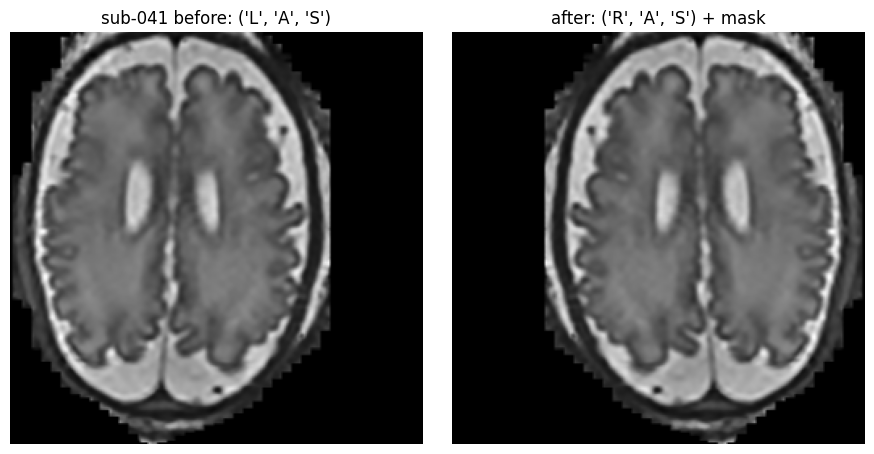

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Pick the first subject that was LAS
img_path, seg_path = next(
    (i, s) for i, s in pairs
    if nib.aff2axcodes(nib.load(i).affine) == ("L", "A", "S")
)

img_before = nib.load(img_path)
img_after = reorient_to_ras(img_before)
seg_after = reorient_to_ras(nib.load(seg_path))

before = img_before.get_fdata()
after = img_after.get_fdata()
mask = np.asarray(seg_after.dataobj)

z = after.shape[2] // 2   # middle axial slice

fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))

axes[0].imshow(before[:, :, z].T, cmap="gray", origin="lower")
axes[0].set_title(f"{img_path.name.split('_')[0]} before: {nib.aff2axcodes(img_before.affine)}")

axes[1].imshow(after[:, :, z].T, cmap="gray", origin="lower")
axes[1].set_title(f"after: {nib.aff2axcodes(img_after.affine)} + mask")

for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

hurray it's flipped !

### 3. Fill empty/NaN values with 0

In [4]:
from src.preprocess import fill_nan

with_bad_values = 0

for img_path, seg_path in pairs:
    img = reorient_to_ras(nib.load(img_path))
    img_filled = fill_nan(img)

    before = img.get_fdata()
    after = img_filled.get_fdata()

    bad_before = np.isnan(before).sum() + np.isinf(before).sum()
    if bad_before > 0:
        with_bad_values += 1
        print(f"{img_path.name} has {bad_before} bad values before filling.")

    assert not np.isnan(after).any() and not np.isinf(after).any(), img_path.name
    assert nib.aff2axcodes(img_filled.affine) == ("R", "A", "S"), img_path.name

print(f"Done: {len(pairs)} images checked, {with_bad_values} had NaN/inf")

Done: 80 images checked, 0 had NaN/inf


cool, there wasn't any problematic data 

### 4. Resample to common spacing

In [ ]:
from src.preprocess import resample_to_spacing

img_path, seg_path = pairs[0]
img = fill_nan(reorient_to_ras(nib.load(img_path)))
seg = reorient_to_ras(nib.load(seg_path))
img_r, seg_r = resample_to_spacing(img, seg, spacing=(0.5, 0.5, 0.5))

print("Spacing before:", img.header.get_zooms()[:3], "after:", img_r.header.get_zooms()[:3])
print("Shape before:  ", img.shape, "after:", img_r.shape, "| mask:", seg_r.shape)
print("Labels before: ", np.unique(np.asarray(seg.dataobj)))
print("Labels after:  ", np.unique(np.asarray(seg_r.dataobj)))
print("Still RAS:", nib.aff2axcodes(img_r.affine))

### 5. Remove background

Before: (256, 256, 256) After: (165, 196, 169) (165, 196, 169)


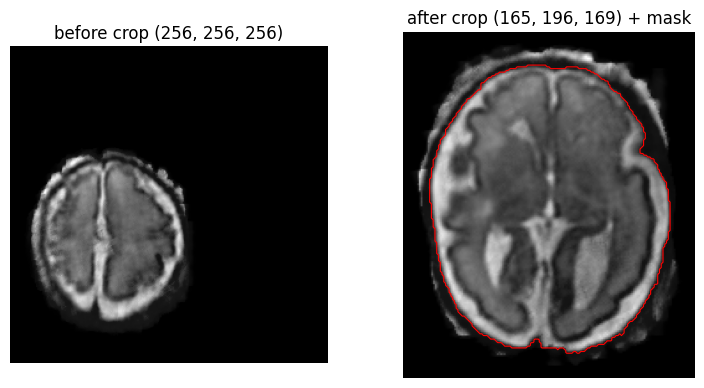

In [ ]:
from src.preprocess import crop_to_foreground

img_path, seg_path = pairs[0]
img = fill_nan(reorient_to_ras(nib.load(img_path)))
seg = reorient_to_ras(nib.load(seg_path))
img_r, seg_r = resample_to_spacing(img, seg, spacing=(0.5, 0.5, 0.5))
img_c, seg_c = crop_to_foreground(img_r, seg_r)

print("Before:", img_r.shape, "After:", img_c.shape, seg_c.shape)

z = img_c.shape[2] // 2
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))
axes[0].imshow(img_r.get_fdata()[:, :, z].T, cmap="gray", origin="lower")
axes[0].set_title(f"before crop {img_r.shape}")
axes[1].imshow(img_c.get_fdata()[:, :, z].T, cmap="gray", origin="lower")
axes[1].contour((np.asarray(seg_c.dataobj)[:, :, z] > 0).T, levels=[0.5], colors="red", linewidths=0.8)
axes[1].set_title(f"after crop {img_c.shape} + mask")
for ax in axes:
    ax.axis("off")
plt.show()


it's normal that they dont look exactly alike. the section isnt the same after cropping


### 6. Pad to a fixed shape

In [9]:
shapes = []
for img_path, seg_path in pairs:
    img = fill_nan(reorient_to_ras(nib.load(img_path)))
    seg = reorient_to_ras(nib.load(seg_path))
    img, seg = resample_to_spacing(img, seg, spacing=(0.5, 0.5, 0.5))
    img, seg = crop_to_foreground(img, seg)
    shapes.append(img.shape)

print("max shape per axis:", np.array(shapes).max(axis=0))

max shape per axis: [229 257 250]


### 7. Normalize intensity values

In [10]:
from src.preprocess import scale_intensity

mins = [nib.load(p).get_fdata(dtype=np.float32).min() for p, _ in pairs]
print("lowest raw intensity across FeTA:", min(mins))

img_path, seg_path = pairs[0]
img = fill_nan(reorient_to_ras(nib.load(img_path)))
img_n = scale_intensity(img)
data = img_n.get_fdata()
print("min / max after:", data.min(), data.max())
print("background still 0:", np.all(data[img.get_fdata() == 0] == 0))

lowest raw intensity across FeTA: 0.0
min / max after: 0.0 1.0
background still 0: True


### 8. Remapping labels -- awaiting response